<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Keras Datasets

_Author: Tim Book_

In [1]:
import os
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import image_dataset_from_directory

In [2]:
train_labels = pd.read_csv('butterflies/Training_set.csv')
train_labels.head()

,filename,label
0,Image_1.jpg,SOUTHERN DOGFACE
1,Image_2.jpg,ADONIS
2,Image_3.jpg,BROWN SIPROETA
3,Image_4.jpg,MONARCH
4,Image_5.jpg,GREEN CELLED CATTLEHEART


In [3]:
train_labels.label = train_labels.label.str.lower().str.replace(' ', '-')
train_labels.head()

,filename,label
0,Image_1.jpg,southern-dogface
1,Image_2.jpg,adonis
2,Image_3.jpg,brown-siproeta
3,Image_4.jpg,monarch
4,Image_5.jpg,green-celled-cattleheart


In [4]:
labels = train_labels.label.unique()
C = len(labels)
print(f"There are {C} total labels of butterfiles")
labels[:5]

There are 75 total labels of butterfiles


array(['southern-dogface', 'adonis', 'brown-siproeta', 'monarch',
       'green-celled-cattleheart'], dtype=object)

First, we'll create the top-level folders. Then, in a loop, all the class-level folders like this:

```
data
└── train
    ├── adonis
    ├── african-giant-swallowtail
    ├── ...
```

In [5]:
def clear_and_mkdir(d):
    if os.path.exists(d):
        shutil.rmtree(d)
    os.mkdir(d)
    
clear_and_mkdir('data')
clear_and_mkdir('data/train')
for label in labels:
    clear_and_mkdir(f'data/train/{label}')

In [6]:
# Peer inside!
!ls data/train | head -10

adonis
african-giant-swallowtail
american-snoot
an-88
appollo
atala
banded-orange-heliconian
banded-peacock
beckers-white
black-hairstreak


Next, we'll move (or copy) each image into its appropriate folder.

In [7]:
train_labels.head()

,filename,label
0,Image_1.jpg,southern-dogface
1,Image_2.jpg,adonis
2,Image_3.jpg,brown-siproeta
3,Image_4.jpg,monarch
4,Image_5.jpg,green-celled-cattleheart


In [8]:
# .iterrows() can be used to loop through the rows of a dataframe.
# We could also have written a creative .apply() here but this is something new!
for i, row in train_labels.head().iterrows():
    file, label = row
    print(f"File is: {file} and label is: {label}")

File is: Image_1.jpg and label is: southern-dogface
File is: Image_2.jpg and label is: adonis
File is: Image_3.jpg and label is: brown-siproeta
File is: Image_4.jpg and label is: monarch
File is: Image_5.jpg and label is: green-celled-cattleheart


In [9]:
# Copy files from the raw structure into our new structure.
# Note this will DUPLICATE! the size of your data. You can use
# shutil.move() instead of .copy() if this is a concern.
for i, row in train_labels.iterrows():
    file, label = row
    src = f'butterflies/train/{file}'
    dest = f'data/train/{label}/{file}'
    shutil.copy(src, dest)

Finally, we can create a `dataset` from this folder using the function we imported.

In [10]:
train_ds = image_dataset_from_directory(
    'data/train',
    batch_size=32,
    subset='training',
    seed=123,
    validation_split=0.2
)

val_ds = image_dataset_from_directory(
    'data/train',
    batch_size=32,
    subset='validation',
    seed=123,
    validation_split=0.2
)

Found 6499 files belonging to 75 classes.
Using 5200 files for training.
Found 6499 files belonging to 75 classes.
Using 1299 files for validation.


In [11]:
for x, y in train_ds.map(lambda x, y: (x / 255, y)):
    break

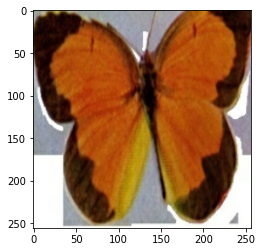

In [12]:
plt.imshow(x[0]);

In [13]:
model = keras.models.Sequential([
    Conv2D(32, 3, activation='relu', input_shape=(256, 256, 3)),
    MaxPooling2D(2),
    Conv2D(64, 3, activation='relu'),
    MaxPooling2D(2),
    Flatten(),
    Dense(16, activation='relu'),
    Dense(C, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='rmsprop',
    metrics=['acc']
)

In [14]:
model.fit(train_ds, validation_data=val_ds, epochs=5)

Epoch 1/5
163/163 [==============================] - 144s 881ms/step - loss: 33.6074 - acc: 0.0163 - val_loss: 4.3173 - val_acc: 0.0231
Epoch 2/5
163/163 [==============================] - 151s 929ms/step - loss: 6.0701 - acc: 0.0194 - val_loss: 4.3174 - val_acc: 0.0231
Epoch 3/5
163/163 [==============================] - 150s 921ms/step - loss: 4.3156 - acc: 0.0194 - val_loss: 4.3177 - val_acc: 0.0231
Epoch 4/5
163/163 [==============================] - 184s 1s/step - loss: 4.3149 - acc: 0.0194 - val_loss: 4.3180 - val_acc: 0.0231
Epoch 5/5
163/163 [==============================] - 300s 2s/step - loss: 4.3143 - acc: 0.0194 - val_loss: 4.3183 - val_acc: 0.0231
